In [36]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import cartopy.feature as cf
from cartopy.util import add_cyclic_point



In [2]:
# Imports

echam_ds = xr.load_dataset('samples/HW310_esm-flat10_RESCUE_echam6_echam_1862.nc', engine="netcdf4")
tracer_ds = xr.load_dataset('samples/HW310_esm-flat10_RESCUE_echam6_tracer_1926.nc', engine="netcdf4")
tracerpl_ds = xr.load_dataset('samples/HW310_esm-flat10_RESCUE_echam6_tracerpl_1946.nc', engine="netcdf4")

In [3]:
echam_ds

<xarray.Dataset> Size: 762MB
Dimensions:         (nhyi: 96, nhym: 95, time: 12, lev: 95, lat: 96, lon: 192,
                     nsp: 2080, nc2: 2)
Coordinates:
  * time            (time) datetime64[ns] 96B 1862-01-31T23:52:00 ... 1862-12...
  * lev             (lev) float64 760B 1.0 2.0 3.0 4.0 ... 92.0 93.0 94.0 95.0
  * lat             (lat) float64 768B 88.57 86.72 84.86 ... -86.72 -88.57
  * lon             (lon) float64 2kB 0.0 1.875 3.75 5.625 ... 354.4 356.2 358.1
Dimensions without coordinates: nhyi, nhym, nsp, nc2
Data variables: (12/147)
    hyai            (nhyi) float64 768B 0.0 1.989 2.693 3.546 ... 0.0 0.0 0.0
    hybi            (nhyi) float64 768B 0.0 0.0 0.0 0.0 ... 0.973 0.9923 1.0
    hyam            (nhym) float64 760B 0.9946 2.341 3.119 ... 36.03 0.0 0.0
    hybm            (nhym) float64 760B 0.0 0.0 0.0 0.0 ... 0.9586 0.9826 0.9961
    tpot            (time, lev, lat, lon) float32 84MB 5.743e+03 ... 271.1
    q               (time, lev, lat, lon) float32 84MB 9.272e-07 ... 0.0003699
    ...              ...
    srad0           (time, lat, lon) float32 885kB 0.0 0.0 0.0 ... 161.3 161.2
    trad0           (time, lat, lon) float32 885kB -166.4 -166.4 ... -182.8
    ustr            (time, lat, lon) float32 885kB -0.02215 ... -0.02809
    vstr            (time, lat, lon) float32 885kB 0.0101 0.009795 ... -0.0122
    evap            (time, lat, lon) float32 885kB -3.18e-07 ... 2.057e-07
    srad0d          (time, lat, lon) float32 885kB 0.0 0.0 0.0 ... 549.3 549.3
Attributes:
    CDI:          Climate Data Interface version 2.4.2 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    institution:  Max Planck Institute for Meteorology
    history:      Mon Jul 06 14:14:01 2026: cdo -O -r -f nc4c -z zip_3 -t /gx...
    CDO:          Climate Data Operators version 2.4.2 (https://mpimet.mpg.de...

In [4]:
# slice dataset
# time format '1862-01-31T23:52:00.000000000'
time_slice = echam_ds.sel(time=slice('1862-01-31T23:52:00.000000000', '1862-02-20T23:52:00.000000000'))
echam_ds.time

lon_slice = echam_ds.sel(lon=slice(10, 15))
lon_slice

# extract variables
echam_ds.sel(lev=1).q  # specific humidity [kg/kg]
echam_ds.sel(time='1862-01-31T23:52:00.000000000').st  # temperature [K]
echam_ds.sel(lat=slice(-25.0, -27.0)).tpot # potential temperature [K]
echam_ds.sel(lat=slice(27, 25)).aclcac # cloud cover
echam_ds.sel(nsp=137) # not sure what nsp is


<xarray.Dataset> Size: 705MB
Dimensions:         (nhyi: 96, nhym: 95, time: 12, lev: 95, lat: 96, lon: 192,
                     nc2: 2)
Coordinates:
  * time            (time) datetime64[ns] 96B 1862-01-31T23:52:00 ... 1862-12...
  * lev             (lev) float64 760B 1.0 2.0 3.0 4.0 ... 92.0 93.0 94.0 95.0
  * lat             (lat) float64 768B 88.57 86.72 84.86 ... -86.72 -88.57
  * lon             (lon) float64 2kB 0.0 1.875 3.75 5.625 ... 354.4 356.2 358.1
Dimensions without coordinates: nhyi, nhym, nc2
Data variables: (12/147)
    hyai            (nhyi) float64 768B 0.0 1.989 2.693 3.546 ... 0.0 0.0 0.0
    hybi            (nhyi) float64 768B 0.0 0.0 0.0 0.0 ... 0.973 0.9923 1.0
    hyam            (nhym) float64 760B 0.9946 2.341 3.119 ... 36.03 0.0 0.0
    hybm            (nhym) float64 760B 0.0 0.0 0.0 0.0 ... 0.9586 0.9826 0.9961
    tpot            (time, lev, lat, lon) float32 84MB 5.743e+03 ... 271.1
    q               (time, lev, lat, lon) float32 84MB 9.272e-07 ... 0.0003699
    ...              ...
    srad0           (time, lat, lon) float32 885kB 0.0 0.0 0.0 ... 161.3 161.2
    trad0           (time, lat, lon) float32 885kB -166.4 -166.4 ... -182.8
    ustr            (time, lat, lon) float32 885kB -0.02215 ... -0.02809
    vstr            (time, lat, lon) float32 885kB 0.0101 0.009795 ... -0.0122
    evap            (time, lat, lon) float32 885kB -3.18e-07 ... 2.057e-07
    srad0d          (time, lat, lon) float32 885kB 0.0 0.0 0.0 ... 549.3 549.3
Attributes:
    CDI:          Climate Data Interface version 2.4.2 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    institution:  Max Planck Institute for Meteorology
    history:      Mon Jul 06 14:14:01 2026: cdo -O -r -f nc4c -z zip_3 -t /gx...
    CDO:          Climate Data Operators version 2.4.2 (https://mpimet.mpg.de...

In [5]:
tracer_ds # contains CO2 and levels 1-95

<xarray.Dataset> Size: 84MB
Dimensions:  (nhyi: 96, nhym: 95, time: 12, lev: 95, lat: 96, lon: 192)
Coordinates:
  * time     (time) datetime64[ns] 96B 1926-01-31T23:52:00 ... 1926-12-31T23:...
  * lev      (lev) float64 760B 1.0 2.0 3.0 4.0 5.0 ... 91.0 92.0 93.0 94.0 95.0
  * lat      (lat) float64 768B 88.57 86.72 84.86 83.0 ... -84.86 -86.72 -88.57
  * lon      (lon) float64 2kB 0.0 1.875 3.75 5.625 ... 352.5 354.4 356.2 358.1
Dimensions without coordinates: nhyi, nhym
Data variables:
    hyai     (nhyi) float64 768B 0.0 1.989 2.693 3.546 ... 72.06 0.0 0.0 0.0
    hybi     (nhyi) float64 768B 0.0 0.0 0.0 0.0 0.0 ... 0.9442 0.973 0.9923 1.0
    hyam     (nhym) float64 760B 0.9946 2.341 3.119 4.061 ... 36.03 0.0 0.0
    hybm     (nhym) float64 760B 0.0 0.0 0.0 0.0 ... 0.9259 0.9586 0.9826 0.9961
    CO2      (time, lev, lat, lon) float32 84MB 0.0006916 ... 0.0007055
Attributes:
    CDI:          Climate Data Interface version 2.2.4 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    institution:  Max Planck Institute for Meteorology
    history:      Sun Dec 28 18:18:19 2025: cdo -O -r -f nc4c -z zip_3 -t /us...
    CDO:          Climate Data Operators version 2.2.2 (https://mpimet.mpg.de...

In [49]:
tracerpl_ds # contains CO2 and pressure levels (plev) in Pa
# also geosp = surface geopotential (orography) [m**2/s**2] and aps surface pressure [Pa]
tracerpl_ds.time

<xarray.DataArray 'time' (time: 12)> Size: 96B
array(['1946-01-31T23:52:00.000000000', '1946-02-28T23:52:00.000000000',
       '1946-03-31T23:52:00.000000000', '1946-04-30T23:52:00.000000000',
       '1946-05-31T23:52:00.000000000', '1946-06-30T23:52:00.000000000',
       '1946-07-31T23:52:00.000000000', '1946-08-31T23:52:00.000000000',
       '1946-09-30T23:52:00.000000000', '1946-10-31T23:52:00.000000000',
       '1946-11-30T23:52:00.000000000', '1946-12-31T23:52:00.000000000'],
      dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 96B 1946-01-31T23:52:00 ... 1946-12-31T23:...
Attributes:
    standard_name:  time
    axis:           T

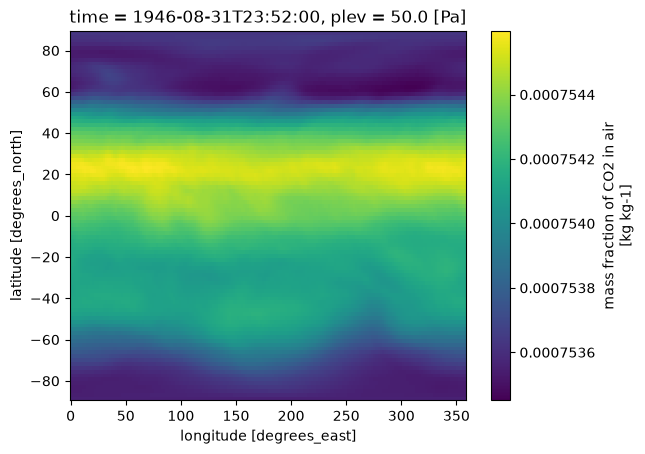

In [7]:
# Plot CO2 data
data = tracerpl_ds.sel(plev=50, time='1946-08-31T23:52:00.000000000')
data["CO2"].plot()

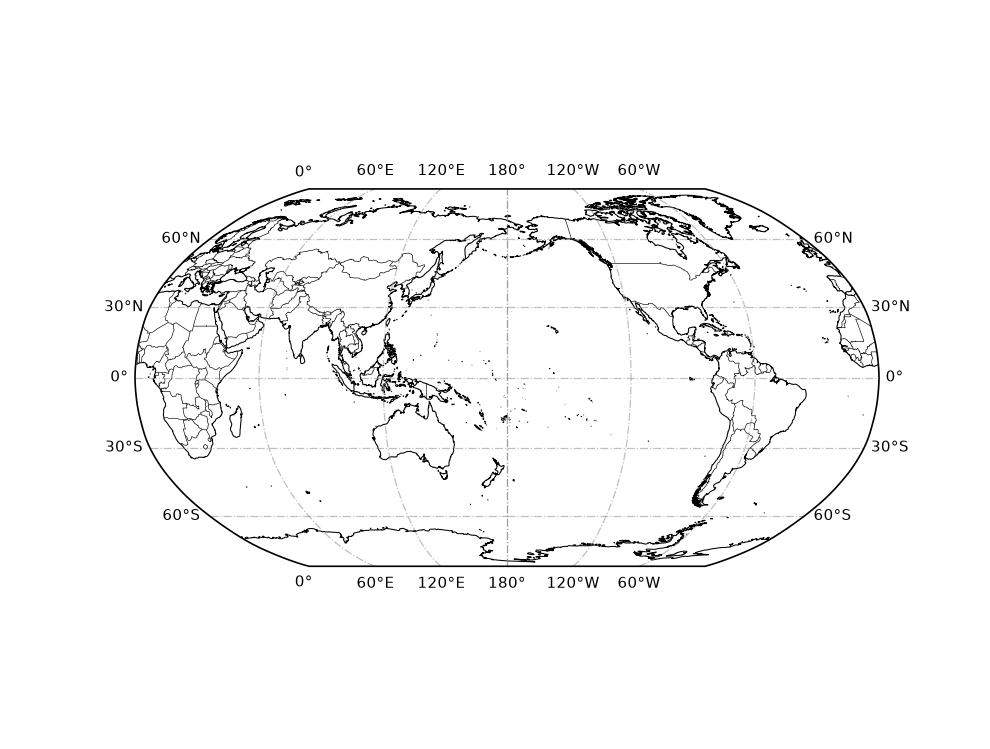

In [14]:
## Setup Cartopy
projection = ccrs.Robinson(central_longitude=180)

# Specify CRS, that will be used to tell the code, where should our data be plotted
crs = ccrs.PlateCarree()

# Now we will create axes object having specific projection 
plt.figure(dpi=150)
ax = plt.axes(projection=projection, frameon=True)

# Draw gridlines in degrees over Mercator map
gl = ax.gridlines(crs=crs, draw_labels=True,
                  linewidth=.6, color='gray', alpha=0.5, linestyle='-.')
gl.xlabel_style = {"size" : 7}
gl.ylabel_style = {"size" : 7}

# To plot borders and coastlines, we can use cartopy feature
ax.add_feature(cf.COASTLINE.with_scale("50m"), lw=0.5)
ax.add_feature(cf.BORDERS.with_scale("50m"), lw=0.3)

# Now, we will specify extent of our map in minimum/maximum longitude/latitude
# Note that these values are specified in degrees of longitude and degrees of latitude
# However, we can specify them in any crs that we want, but we need to provide appropriate
# crs argument in ax.set_extent

# lon_min = -20
# lon_max = 45
# lat_min = 34
# lat_max = 60

## crs is PlateCarree -> we are explicitly telling axes, that we are creating bounds that are in degrees
# ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=crs)
plt.title(f"Sample Global Map")
plt.show()

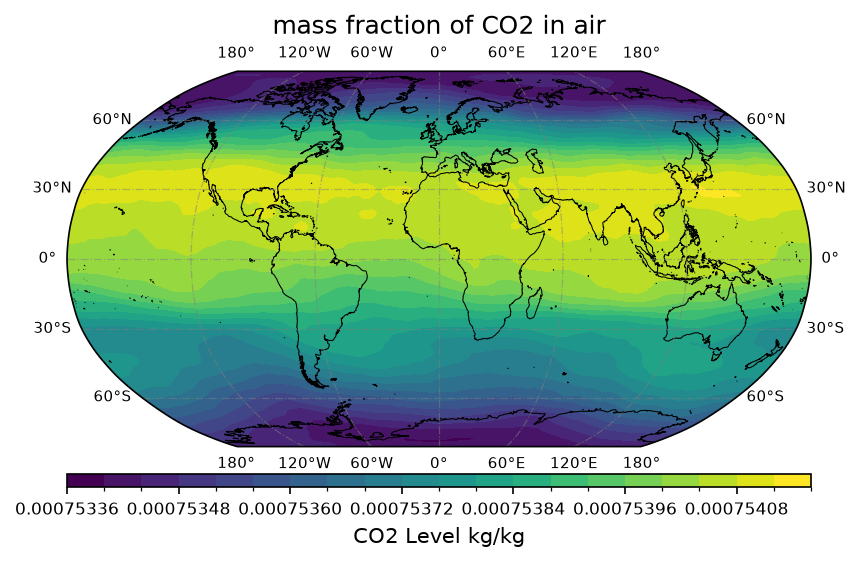

In [40]:
def wrap_data(data, key):
    da = data[key]
    lon_idx = list(da.dims).index('lon')
    cyclic_data, cyclic_lons = add_cyclic_point(da.values, coord=da.lon.values, axis=lon_idx)
    new_coords = dict(da.coords)
    new_coords['lon'] = cyclic_lons
    
    cyclic_da = xr.DataArray(
        cyclic_data,
        coords=new_coords,
        dims=da.dims,
        attrs=da.attrs
    )
    return cyclic_da

def map_setup():
    projection = ccrs.Robinson()
    crs = ccrs.PlateCarree()
    plt.figure(dpi=150)
    ax = plt.axes(projection=projection, frameon=True)
    gl = ax.gridlines(crs=crs, draw_labels=True,
                  linewidth=.6, color='gray', alpha=0.5, linestyle='-.')
    gl.xlabel_style = {"size" : 7}
    gl.ylabel_style = {"size" : 7}
    ax.add_feature(cf.COASTLINE.with_scale("50m"), lw=0.5)
    # ax.add_feature(cf.BORDERS.with_scale("50m"), lw=0.3)
    return ax


def plot_dataset(data, key):
    # data repair
    data = wrap_data(data, key)
    ax = map_setup()

    # plot data
    cbar_kwargs = {'orientation':'horizontal', 'shrink':1, "pad":.05, 'aspect':60, 'label':'CO2 Level kg/kg'}#, 'format':'%4.2e'
    contour_plot = data.plot.contourf(ax=ax, transform=ccrs.PlateCarree(), cbar_kwargs=cbar_kwargs, levels=21)
    contour_plot.colorbar.ax.tick_params(labelsize="small")

    # ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=crs)
    plt.title(data.long_name)
    plt.show()

sliced = tracerpl_ds.sel(plev=20, time='1946-08-31T23:52:00.000000000')
plot_dataset(sliced, "CO2")
